<a href="https://colab.research.google.com/github/AnastasyaIrsyad/ProbStat/blob/main/P4_ProbStat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

import pandas digunakan untuk mengimpor library Pandas ke dalam Python. as itu alias. pd itu singkatan yang digunakan agar penulisan kode pandas lebih singkat.

In [37]:
import matplotlib.pyplot as plt

impor library matplotlib digunakan untuk membuat visualisasi atau grafik dari data.
*   pyplot = bagian dari matplotlib untuk membuat grafik.
*   as plt = memberi nama singkat dari matplotlib.pyplot menjadi plt.

In [5]:
# Tabel Data
path = r"tasya.xlsx"
dataraw = pd.read_excel(path)
print(dataraw)

           NIM                Name  Quiz  UTS  UAS     NA Grade
0   2455301214    Anastasya Irsyad    90   88   94  90.74     A
1       120001            John Doe    85   78   90  84.44     A
2       120005          Jane Smith    92   88   94  91.38     A
3       120017     Michael Johnson    48   65   56  56.41     C
4       120018         Emily Brown    90   85   88  87.65     A
5       120022     Daniel Martinez    75   80   77  77.35    AB
6       120024        Sarah Wilson    88   70   65  74.01     B
7       120025        David Garcia    75   70   75  73.35     B
8       120027         Jessica Lee    95   91   96  94.03     A
9       120034       Matthew Davis    79   84   78  80.30    AB
10      120035  Jennifer Rodriguez    42   48   63  51.33     C
11      120036       Andrew Taylor    53   64   59  58.73     C
12      120038    Amanda Hernandez    91   95   90  91.97     A
13      120039   Christopher Clark    76   81   75  77.30    AB
14      120046  Elizabeth Martinez    89

kode diatas digunakan untuk membaca data dari file tasya.xlsx menggunakan library Pandas. data yang udah dibaca disimpan ke dalam variabel dataraw dan kemudian ditampilkan seluruh isi data ke output menggunakan sintaks print.

In [6]:
# Tabel Frekuensi
datafrq = pd.crosstab(index=dataraw["Grade"], columns="Frekuensi")
print(datafrq)

col_0  Frekuensi
Grade           
A             13
AB             7
B              4
BC             1
C              5
D              1


Kode diatas ini digunakan untuk membuat tabel frekuensi berdasarkan nilai pada kolom Grade. Jadi, setiap grade akan dihitung berapa kali muncul dalam data.

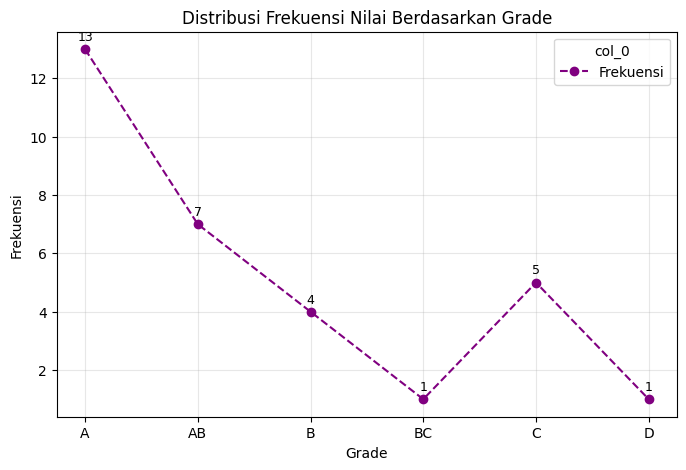

In [50]:
# Grafik Garis
data = datafrq.plot(title='Distribusi Frekuensi Nilai Berdasarkan Grade', # title =memberi judul grafik
                    marker='o',        # memberi tanda bulat pada setiap titik data
                    linestyle='--',    # membuat garis putus-putus
                    color='purple',    # Warna ungu pada garis
                    figsize=(8,5))     # menentukan ukuran grafik
data.set_xlabel('Grade')               # memberi nama sumbu X = Grade
data.set_ylabel('Frekuensi')           # memberi nama sumbu Y = Frekuensi
data.grid(True, alpha=0.3)             # garis bantu pada grafik

# tambah label angka di tiap titik
for i, v in enumerate(datafrq['Frekuensi']):
    data.text(i, v+0.3, str(v), ha='center', fontsize=9)

plt.show()  # menampilkan grafik

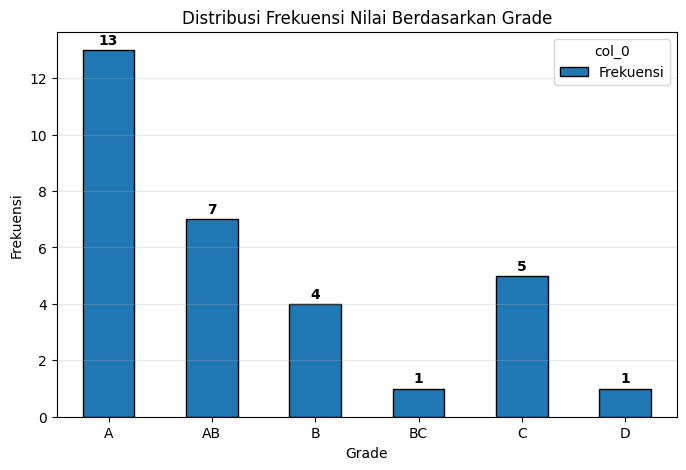

In [56]:
# Grafik Batang
data = datafrq.plot(kind='bar', rot=0, figsize=(8,5),
                     title='Distribusi Frekuensi Nilai Berdasarkan Grade',
                     legend=False, edgecolor='black')
data.set_xlabel('Grade')
data.set_ylabel('Frekuensi')
data.grid(axis='y', alpha=0.3)

# tambah label angka di atas tiap batang
for i, v in enumerate(datafrq['Frekuensi']):
    data.text(i, v+0.2, str(v), ha='center', fontweight='bold')

plt.show()

*   rot=0 --> membuat tulisan Grade pada sumbu X tetap horizontal.
*   figsize=(8,5) --> menentukan ukuran grafik.
*   title --> memberikan judul grafik.
*   legend=False --> menghilangkan legenda karena sudah jelas berdasarkan Grade.
*   edgecolor='black' --> warna hitam pada garis tepi batang.
*   xlabel --> beri nama sumbu X = Grade.
*   ylabel --> beri nama sumbu Y = Frekuensi.
*   grid(axis='y') --> menambahkan garis bantu pada sumbu Y.


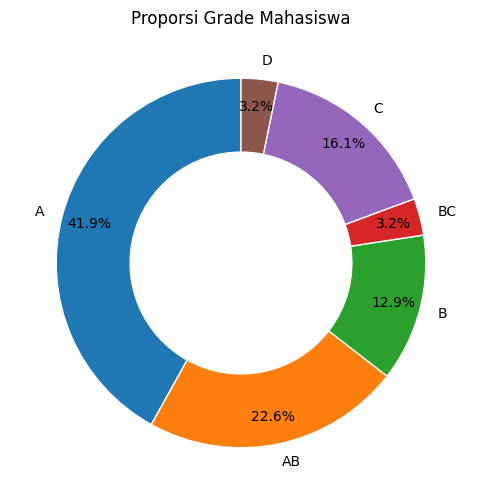

In [53]:
# Donut Chart
donat = datafrq.plot(kind='pie', y='Frekuensi', figsize=(6,6),
                             autopct='%1.1f%%', startangle=90,
                             pctdistance=0.85, legend=False,
                             wedgeprops=dict(width=0.4, edgecolor='white'),
                             title='Proporsi Grade Mahasiswa')
donat.set_ylabel('');

*   datafrq.plot(kind='pie') --> membuat grafik berbentuk pie.
*   y='Frekuensi' --> menggunakan kolom Frekuensi sebagai nilai grafik.
*   figsize=(6,6) --> mengatur ukuran grafik.
*   autopct='%1.1f%%' --> menampilkan persentase dengan 1 angka dibelakang koma.
*   startangle=90 --> menentukan posisi awal grafik dari sudut 90°.
*   pctdistance=0.85 --> mengatur posisi tulisan persentase agar berada didalam warna grafik.
*   wedgeprops=dict(width=0.4, edgecolor='white') --> membuat bagian tengah grafik menjadi lubang, sehingga bentuknya menjadi donat.
*   title --> judul grafik.
*   donat.set_ylabel('') --> menghilangkan label sumbu Y yang tidak diperlukan pada grafik pie/donat.


In [11]:
# Statistika Deskriptif
dataraw["NA"] = pd.to_numeric(dataraw["NA"], errors='coerce') # kolom NA diubah jadi angka
dt = dataraw["NA"]                  # mengambil kolom NA

# menghitung statistik dasar seperti jumlah data, rata-rata, standar deviasi,
# nilai minimum, kuartil, dan maksimum.
stats = dt.describe()
stats["Standard Error"] = dt.sem()  # menghitung Standard Error
stats["Median"] = dt.median()       # mencari nilai tengah (Median)
stats["Mode"] = dt.mode().iloc[0]   # mencari nilai yang paling sering muncul (Modus)
stats["variance"] = dt.var()        # hitung varian
stats["range"] = dt.max() - dt.min()  # hitung range
stats["skewness"] = dt.skew()       # untuk melihat kemencengan distribusi data
stats["kurtosis"] = dt.kurtosis()   # untuk melihat bentuk distribusi data
print(stats)                        # menampilkan semua perhitungan

count              31.000000
mean               76.689677
std                13.494580
min                46.010000
25%                68.800000
50%                79.300000
75%                87.470000
max                94.030000
Standard Error      2.423698
Median             79.300000
Mode               77.300000
variance          182.103690
range              48.020000
skewness           -0.703566
kurtosis           -0.492634
Name: NA, dtype: float64
